# Predicción de cancelación y segmentación de clientes en Model Fitness

### Machine Learning aplicado a retención de clientes

## Objetivo

Analizar el comportamiento de los clientes de la cadena de gimnasios Model Fitness para identificar los factores asociados con la cancelación de membresías, desarrollar un modelo capaz de predecir el riesgo de abandono y segmentar a los clientes de acuerdo con sus características y comportamiento.

## Herramientas utilizadas

- Python
- Pandas
- Matplotlib
- Seaborn
- Scikit-learn
- SciPy
- Regresión Logística
- Random Forest
- K-Means
- Clustering jerárquico

## Análisis realizado

El proyecto incluye análisis exploratorio de datos, comparación de clientes que permanecen y cancelan, análisis de correlaciones, construcción y evaluación de modelos de clasificación, segmentación de clientes mediante clustering y elaboración de recomendaciones de negocio orientadas a mejorar la retención.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import KMeans

## 1. Importación y exploración inicial de los datos

In [3]:
df = pd.read_csv('gym_churn_us.csv')

display(df.head())

,gender,Near_Location,Partner,Promo_friends,Phone,Contract_period,Group_visits,Age,Avg_additional_charges_total,Month_to_end_contract,Lifetime,Avg_class_frequency_total,Avg_class_frequency_current_month,Churn
0,1,1,1,1,0,6,1,29,14.227470,5.0,3,0.020398,0.000000,0
1,0,1,0,0,1,12,1,31,113.202938,12.0,7,1.922936,1.910244,0
2,0,1,1,0,1,1,0,28,129.448479,1.0,2,1.859098,1.736502,0
3,0,1,1,1,1,12,1,33,62.669863,12.0,2,3.205633,3.357215,0
4,1,1,1,1,1,1,0,26,198.362265,1.0,3,1.113884,1.120078,0


Se carga el archivo CSV con la información de los clientes de Model Fitness y se imprimen las primeras filas para confirmar que los datos se importaron correctamente y están listos para el análisis.

## 2. Análisis exploratorio de datos (EDA)

In [4]:
df.info()

print(f'\nValores ausentes: {df.isna().sum().sum()}')
print(f'Registros duplicados: {df.duplicated().sum()}')

display(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 14 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   gender                             4000 non-null   int64  
 1   Near_Location                      4000 non-null   int64  
 2   Partner                            4000 non-null   int64  
 3   Promo_friends                      4000 non-null   int64  
 4   Phone                              4000 non-null   int64  
 5   Contract_period                    4000 non-null   int64  
 6   Group_visits                       4000 non-null   int64  
 7   Age                                4000 non-null   int64  
 8   Avg_additional_charges_total       4000 non-null   float64
 9   Month_to_end_contract              4000 non-null   float64
 10  Lifetime                           4000 non-null   int64  
 11  Avg_class_frequency_total          4000 non-null   float64
 12  Avg

,gender,Near_Location,Partner,Promo_friends,Phone,Contract_period,Group_visits,Age,Avg_additional_charges_total,Month_to_end_contract,Lifetime,Avg_class_frequency_total,Avg_class_frequency_current_month,Churn
count,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000
mean,0.510250,0.845250,0.486750,0.308500,0.903500,4.681250,0.412250,29.184250,146.943728,4.322750,3.724750,1.879020,1.767052,0.265250
std,0.499957,0.361711,0.499887,0.461932,0.295313,4.549706,0.492301,3.258367,96.355602,4.191297,3.749267,0.972245,1.052906,0.441521
min,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,18.000000,0.148205,1.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,27.000000,68.868830,1.000000,1.000000,1.180875,0.963003,0.000000
50%,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,29.000000,136.220159,1.000000,3.000000,1.832768,1.719574,0.000000
75%,1.000000,1.000000,1.000000,1.000000,1.000000,6.000000,1.000000,31.000000,210.949625,6.000000,5.000000,2.536078,2.510336,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,12.000000,1.000000,41.000000,552.590740,12.000000,31.000000,6.023668,6.146783,1.000000


El dataset contiene 4,000 registros y no presenta valores ausentes ni registros duplicados.

Las variables muestran diferentes magnitudes y escalas. Por ejemplo, `Avg_additional_charges_total` presenta valores considerablemente mayores que variables como `Age` o las frecuencias de visita. Esta diferencia será relevante posteriormente, ya que será necesario estandarizar las características antes de aplicar los algoritmos de clustering.

In [5]:
display(df.groupby('Churn').mean())

,gender,Near_Location,Partner,Promo_friends,Phone,Contract_period,Group_visits,Age,Avg_additional_charges_total,Month_to_end_contract,Lifetime,Avg_class_frequency_total,Avg_class_frequency_current_month
Churn,,,,,,,,,,,,,
0,0.510037,0.873086,0.534195,0.353522,0.903709,5.747193,0.464103,29.976523,158.445715,5.283089,4.711807,2.024876,2.027882
1,0.510839,0.768143,0.355325,0.183789,0.902922,1.728558,0.268615,26.989632,115.082899,1.662582,0.990575,1.474995,1.044546


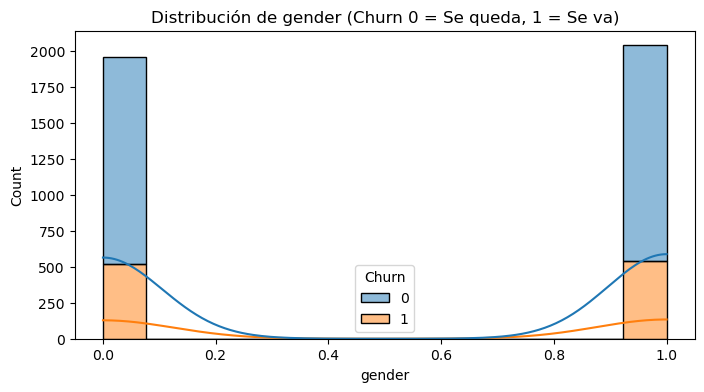

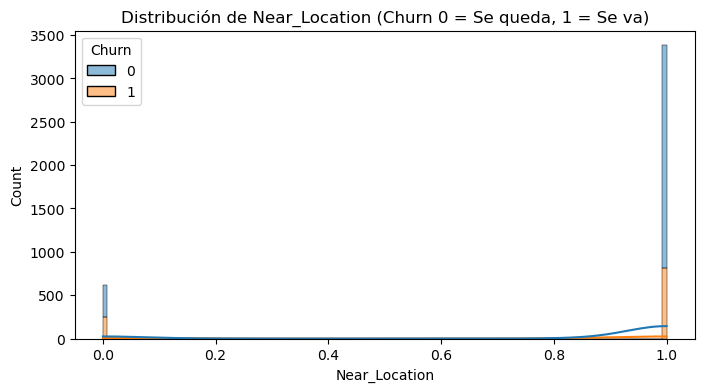

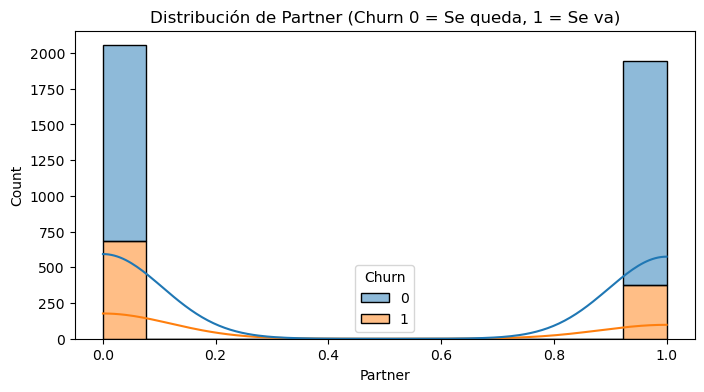

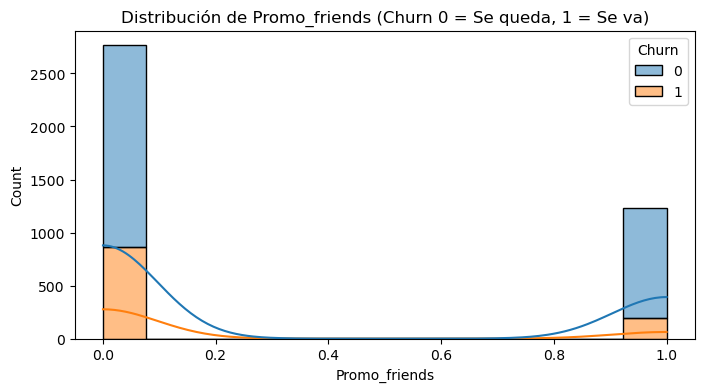

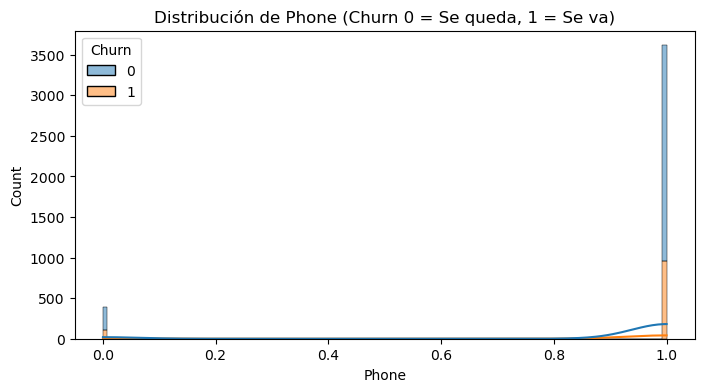

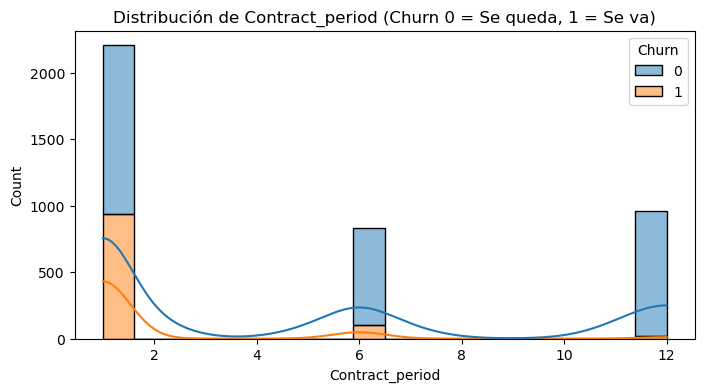

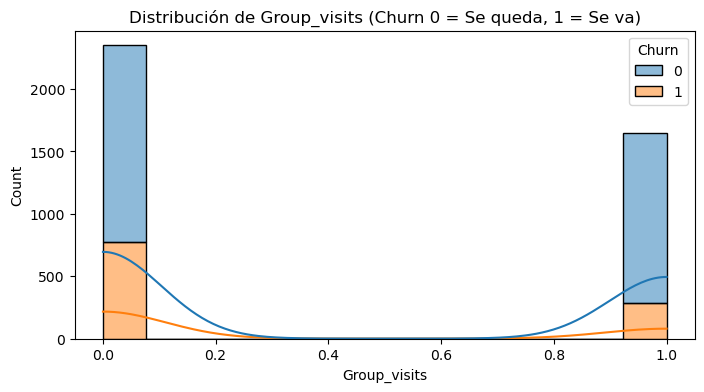

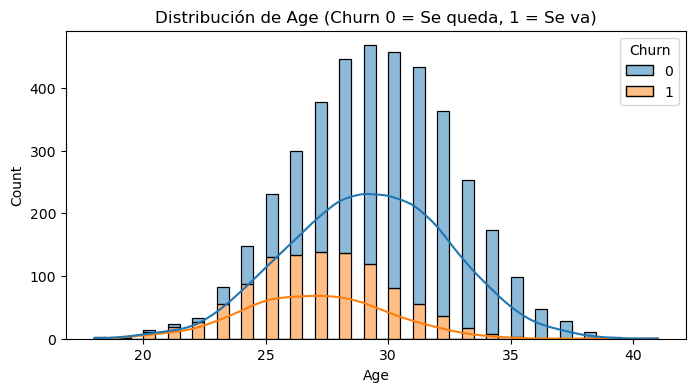

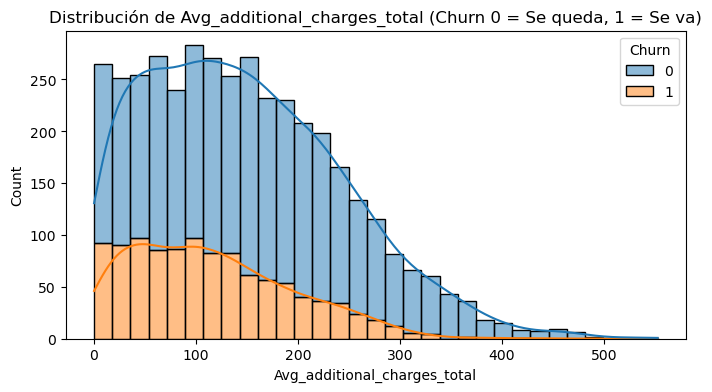

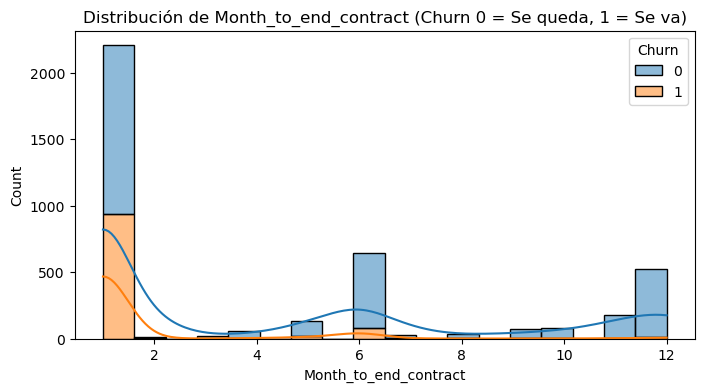

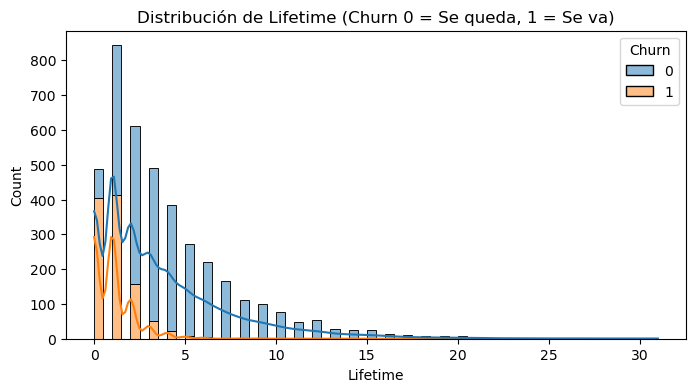

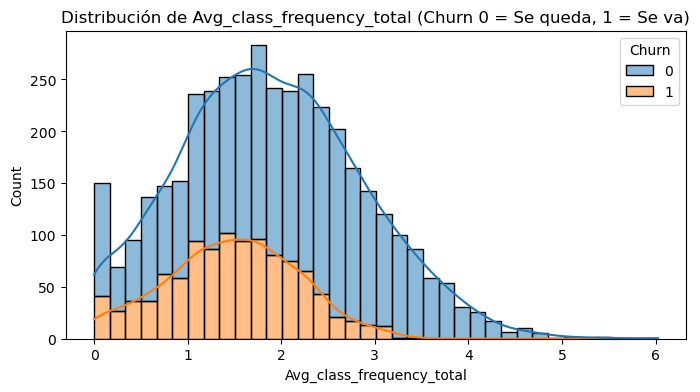

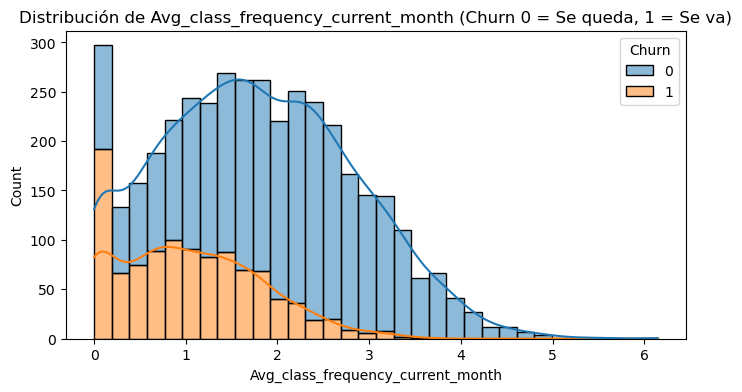

In [6]:
features = df.drop('Churn', axis=1).columns

for col in features:
    plt.figure(figsize=(8, 4))
    sns.histplot(data=df, x=col, hue='Churn', kde=True, multiple="stack")
    plt.title(f'Distribución de {col} (Churn 0 = Se queda, 1 = Se va)')
    plt.show()

Las personas que se quedan tienden a tener contratos más largos (`Contract_period`), viven o trabajan más cerca del gimnasio (`Near_Location`) y asisten con mayor frecuencia a clases grupales y en general. Los que cancelan suelen tener contratos de un solo mes.

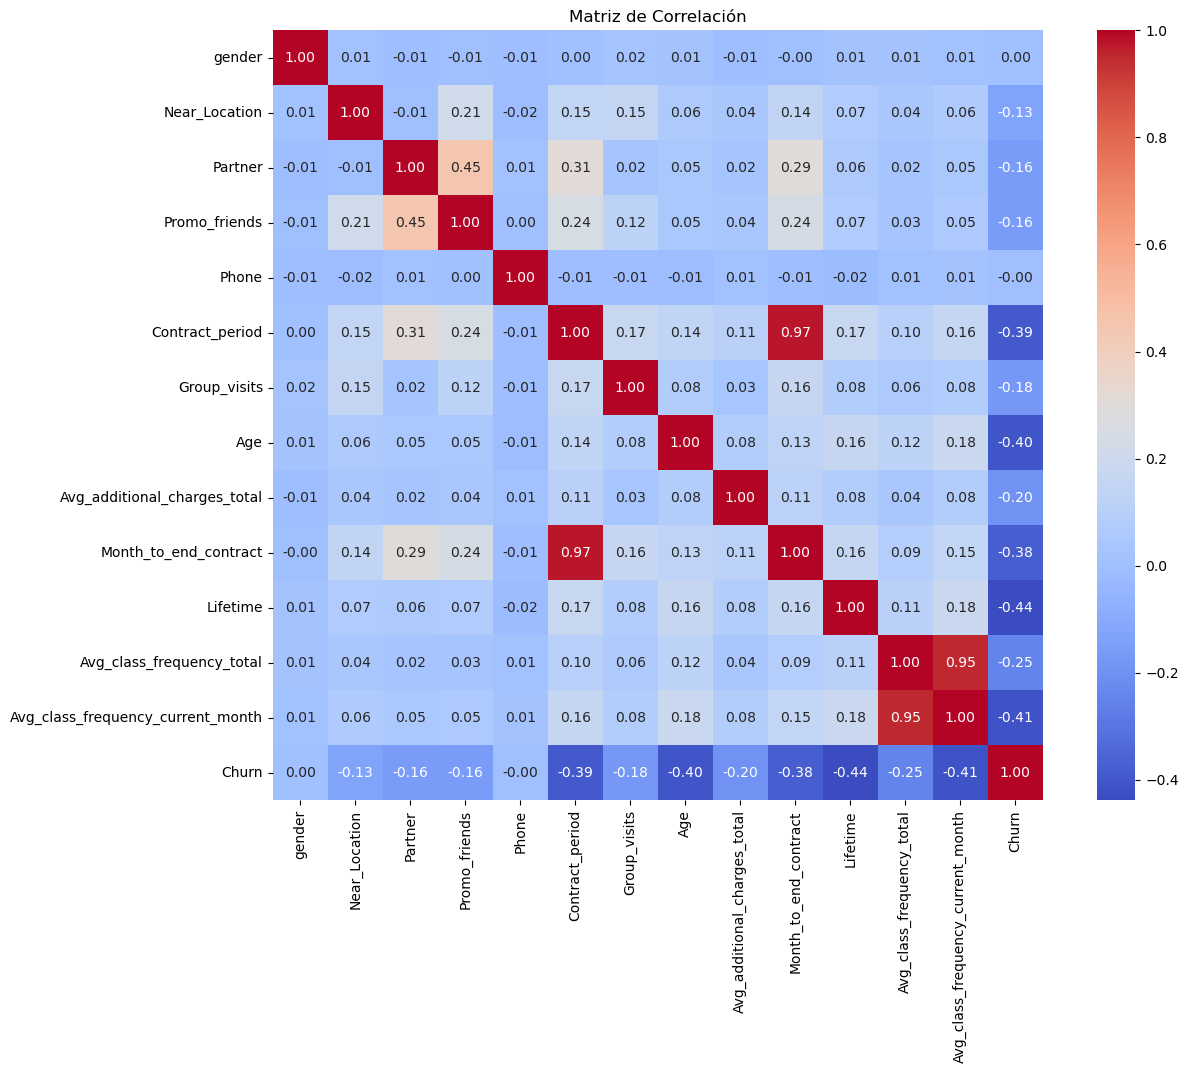

In [7]:
plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', square=True)
plt.title('Matriz de Correlación')
plt.show()

Se observa una fuerte multicolinealidad entre `Contract_period` y `Month_to_end_contract`, así como entre `Avg_class_frequency_current_month` y `Avg_class_frequency_total`. El resto de las variables no presentan correlaciones lo suficientemente altas como para afectar negativamente a los modelos predictivos.

## 3. Modelos predictivos de cancelación de clientes

In [8]:
X = df.drop('Churn', axis=1)
y = df['Churn']

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

def print_metrics(y_true, y_pred, title):
    print(title)
    print(f"Exactitud (Accuracy): {accuracy_score(y_true, y_pred):.3f}")
    print(f"Precisión (Precision): {precision_score(y_true, y_pred):.3f}")
    print(f"Recall: {recall_score(y_true, y_pred):.3f}")
    print("-" * 35)

lr_model = LogisticRegression(random_state=42, solver='liblinear')
lr_model.fit(X_train, y_train)
lr_predictions = lr_model.predict(X_val)

rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_val)

print_metrics(y_val, lr_predictions, "Métricas - Regresión Logística")
print_metrics(y_val, rf_predictions, "Métricas - Bosque Aleatorio")

Métricas - Regresión Logística
Exactitud (Accuracy): 0.924
Precisión (Precision): 0.890
Recall: 0.797
-----------------------------------
Métricas - Bosque Aleatorio
Exactitud (Accuracy): 0.910
Precisión (Precision): 0.849
Recall: 0.782
-----------------------------------


Se entrenaron dos modelos de clasificación para predecir la cancelación de clientes: Regresión Logística y Random Forest.

La **Regresión Logística** obtuvo los mejores resultados en el conjunto de validación:

- Accuracy: **0.924**
- Precision: **0.890**
- Recall: **0.797**

El modelo Random Forest obtuvo un Accuracy de 0.910, Precision de 0.849 y Recall de 0.782.

Por lo tanto, la Regresión Logística mostró un mejor desempeño en las tres métricas evaluadas. El Recall resulta especialmente relevante para el objetivo de negocio, ya que representa la capacidad del modelo para identificar correctamente a los clientes que realmente presentan riesgo de cancelación.

## 4. Segmentación de clientes mediante clustering

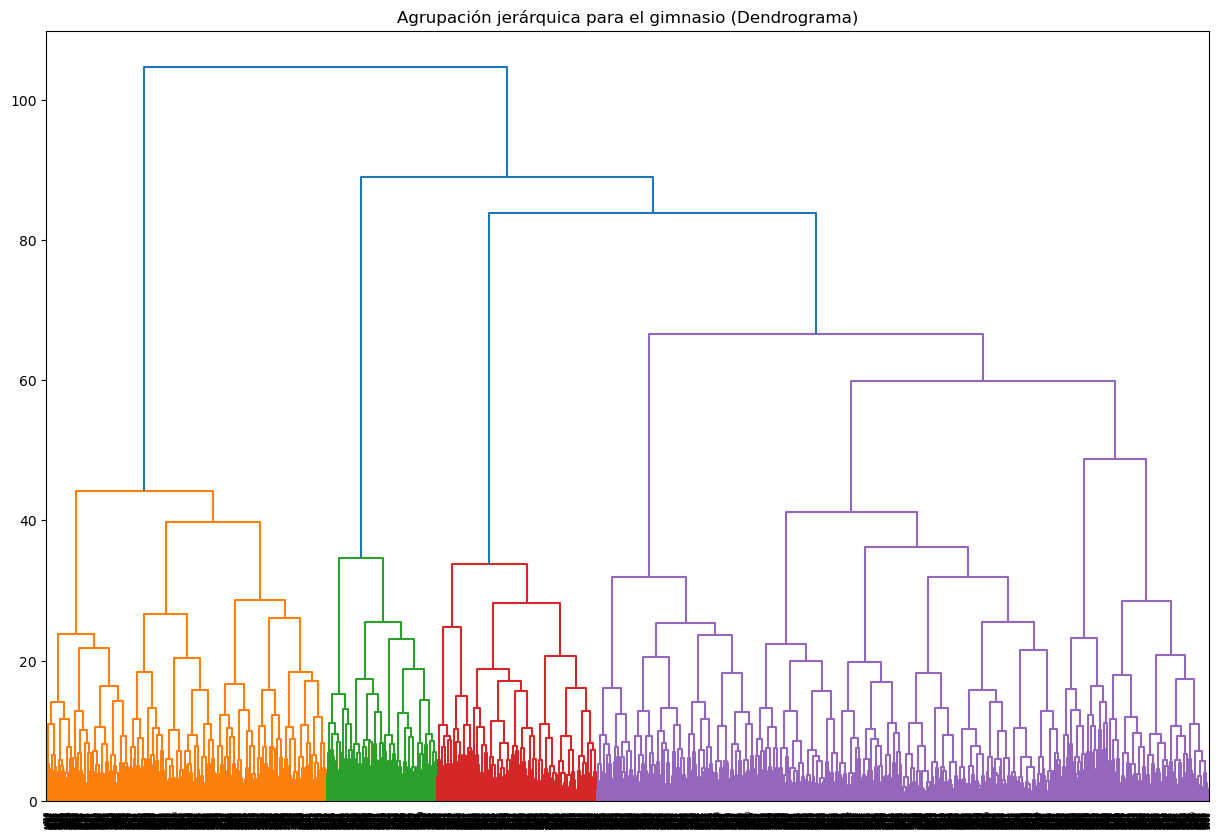

In [9]:
X_sc = StandardScaler().fit_transform(df.drop('Churn', axis=1))

linked = linkage(X_sc, method='ward')

plt.figure(figsize=(15, 10))
dendrogram(linked, orientation='top')
plt.title('Agrupación jerárquica para el gimnasio (Dendrograma)')
plt.show()

### Interpretación del dendrograma

El dendrograma muestra la existencia de diferentes grupos de clientes con características similares y permite observar separaciones entre conjuntos a distintas distancias.

La estructura jerárquica sugiere la presencia de varios segmentos diferenciados. Para continuar con el análisis y mantener una segmentación suficientemente detallada, se utilizarán cinco clústeres mediante K-Means, de acuerdo con el criterio establecido para el proyecto.

El clustering permitirá posteriormente comparar las características y las tasas de cancelación de cada segmento.

In [10]:
km = KMeans(n_clusters=5, random_state=42)
labels = km.fit_predict(X_sc)

df['cluster'] = labels

display(df.groupby('cluster').mean())

/lib/python3.14/site-packages/threadpoolctl.py:1135: RuntimeWarning: JsProxy.as_object_map() is deprecated. Use as_py_json() instead.
  for filepath in LDSO.loadedLibsByName.as_object_map():


,gender,Near_Location,Partner,Promo_friends,Phone,Contract_period,Group_visits,Age,Avg_additional_charges_total,Month_to_end_contract,Lifetime,Avg_class_frequency_total,Avg_class_frequency_current_month,Churn
cluster,,,,,,,,,,,,,,
0,0.484801,0.698363,0.301637,0.007015,0.899454,1.733437,0.255651,28.074825,127.131782,1.657833,2.089634,1.256531,0.991781,0.587685
1,0.494471,0.947867,0.791469,0.998420,0.906793,2.740916,0.431280,28.903633,139.456908,2.540284,3.529226,1.619489,1.488508,0.285940
2,0.464396,0.913313,0.766254,0.493808,0.925697,10.495356,0.506192,30.091331,164.190347,9.484520,4.693498,2.888801,2.886027,0.013932
3,0.547794,0.937500,0.742647,0.424632,0.863971,11.194853,0.575368,29.720588,167.670439,10.347426,4.818015,1.154578,1.139605,0.042279
4,0.568233,0.878076,0.178971,0.048098,0.914989,2.120805,0.456376,29.993289,155.602830,2.013423,4.844519,2.667290,2.650122,0.105145


Los clústeres muestran perfiles de clientes claramente diferenciados.

El **clúster 2** destaca por presentar contratos de mayor duración, una frecuencia de asistencia elevada y una tasa de cancelación muy baja.

En contraste, el **clúster 0** concentra clientes con contratos más cortos, menor frecuencia de asistencia durante el mes actual y menor antigüedad como clientes.

Estas diferencias sugieren que la duración del contrato, la frecuencia de asistencia y la antigüedad del cliente están asociadas con distintos niveles de riesgo de cancelación.

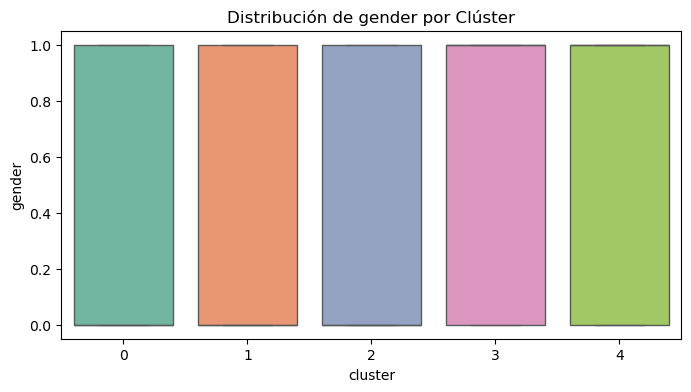

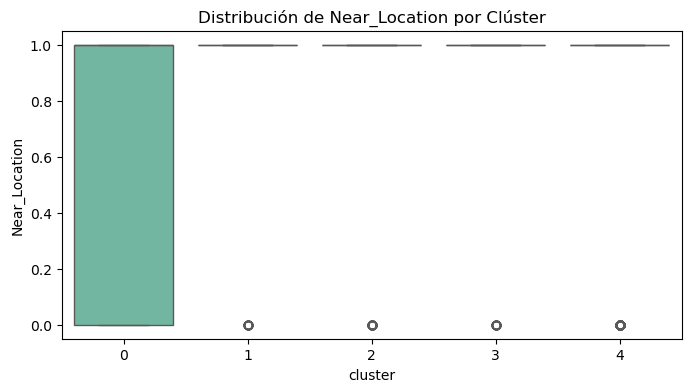

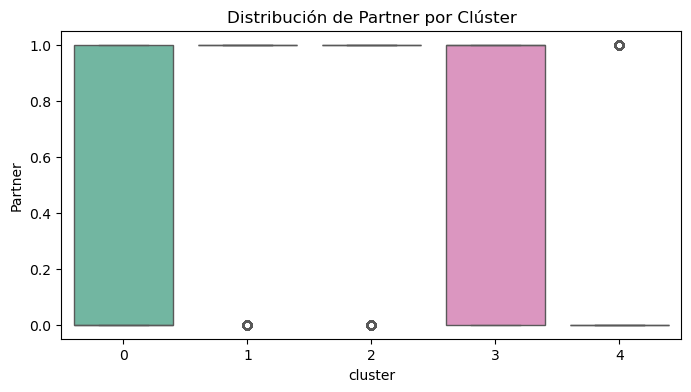

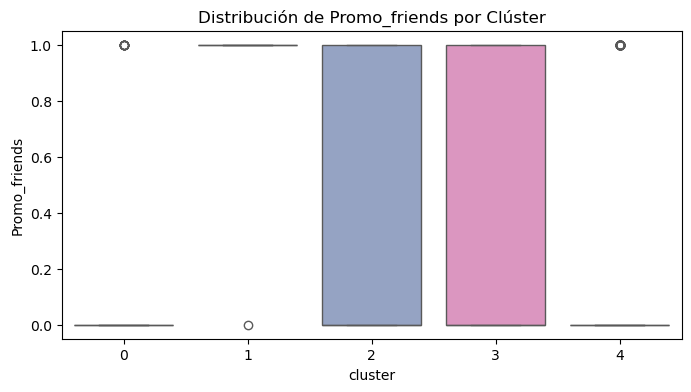

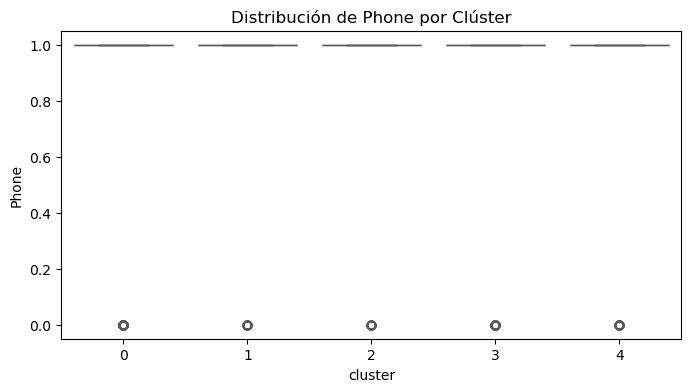

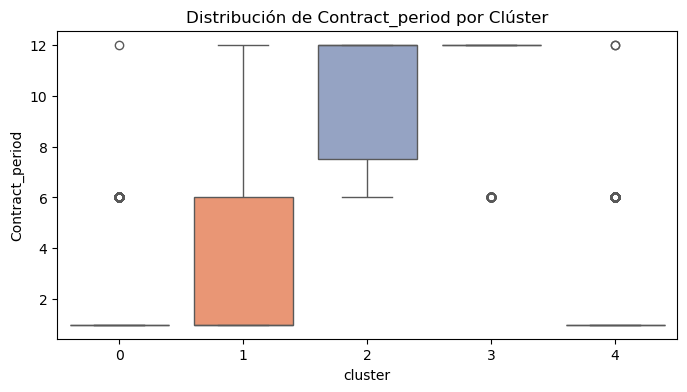

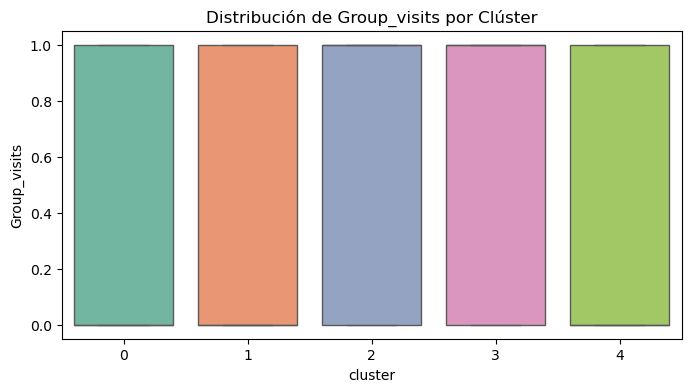

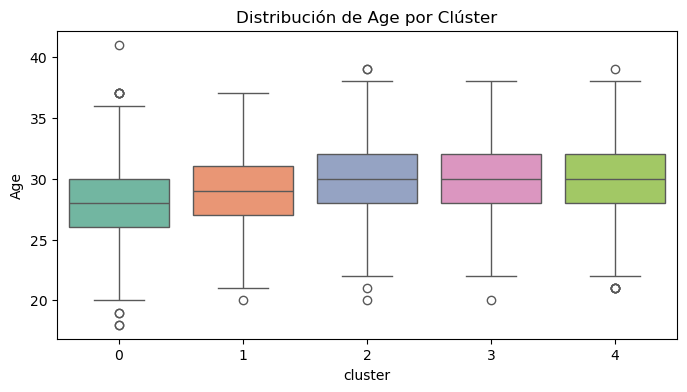

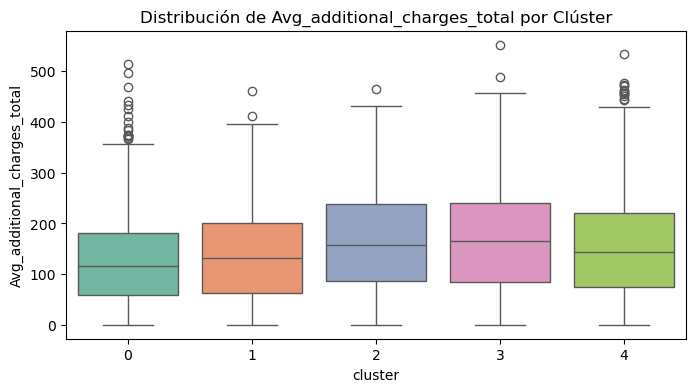

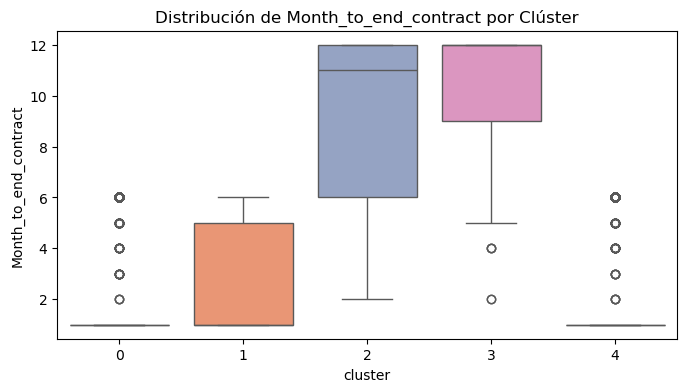

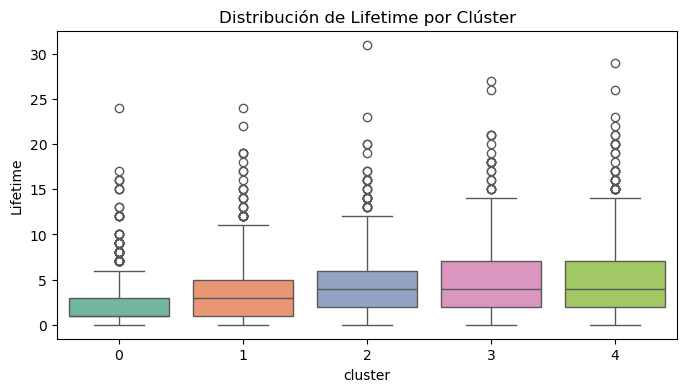

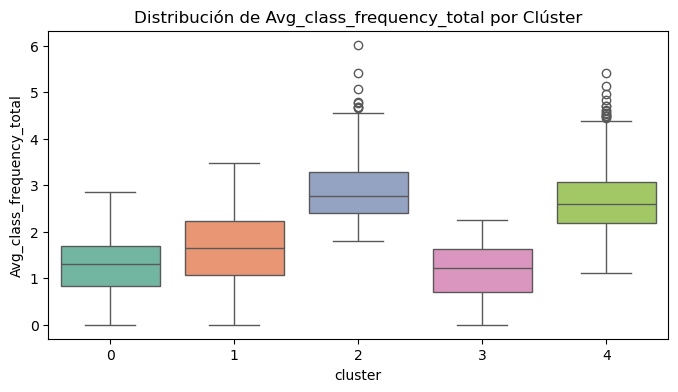

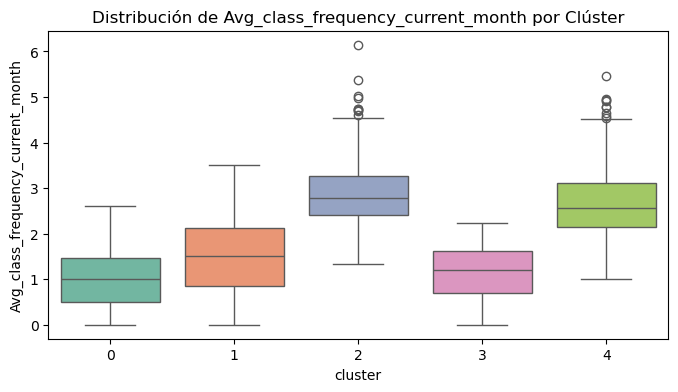

Tasa de cancelación por clúster:


,cluster,Churn
0,0,0.587685
1,1,0.285940
4,4,0.105145
3,3,0.042279
2,2,0.013932


In [11]:
features_to_plot = df.drop(['Churn', 'cluster'], axis=1).columns

for col in features_to_plot:
    plt.figure(figsize=(8, 4))
    sns.boxplot(
    x='cluster',
    y=col,
    hue='cluster',
    data=df,
    palette='Set2',
    legend=False
)
    plt.title(f'Distribución de {col} por Clúster')
    plt.show()

churn_rate = df.groupby('cluster')['Churn'].mean().reset_index()
churn_rate = churn_rate.sort_values(by='Churn', ascending=False)
print("Tasa de cancelación por clúster:")
display(churn_rate)

Las tasas de cancelación muestran diferencias importantes entre los segmentos.

El **clúster 0** presenta el mayor riesgo de cancelación, con una tasa aproximada de **58.77%**. Este grupo se caracteriza por contratos cortos (promedio de aproximadamente 1.73 meses), menor frecuencia de asistencia durante el mes actual y menor antigüedad como cliente.

En contraste, el **clúster 2** presenta la menor tasa de cancelación, aproximadamente **1.39%**. Sus clientes se caracterizan por contratos de mayor duración (promedio de aproximadamente 10.50 meses), alta frecuencia de asistencia y una relación más estable con el gimnasio.

El clúster 1 presenta una tasa de cancelación de aproximadamente 28.59%, mientras que los clústeres 4 y 3 muestran tasas considerablemente menores, de aproximadamente 10.51% y 4.23%, respectivamente.

Estos resultados permiten identificar segmentos prioritarios para implementar estrategias diferenciadas de retención.

## 5. Conclusiones y recomendaciones de negocio

## Conclusiones

El análisis permitió identificar perfiles de clientes con niveles de riesgo de cancelación considerablemente diferentes.

El modelo de **Regresión Logística** presentó el mejor desempeño predictivo, alcanzando un Accuracy de **92.4%**, Precision de **89.0%** y Recall de **79.7%** en el conjunto de validación.

La segmentación mediante K-Means mostró que el **clúster 0** representa el segmento de mayor riesgo, con una tasa de cancelación aproximada del **58.77%**. Este grupo presenta contratos más cortos, menor frecuencia de asistencia durante el mes actual y menor antigüedad como cliente.

En contraste, el **clúster 2** presenta una tasa de cancelación cercana al **1.39%** y se caracteriza por contratos de mayor duración, una frecuencia de asistencia elevada y una relación más estable con el gimnasio.

## Recomendaciones

1. **Priorizar a los clientes con alto riesgo de cancelación.**  
   Utilizar las predicciones del modelo para identificar anticipadamente clientes con comportamientos similares a los segmentos de mayor riesgo y dirigir hacia ellos acciones específicas de retención.

2. **Promover contratos de mayor duración.**  
   Los segmentos con contratos largos presentan menores tasas de cancelación. Se pueden diseñar incentivos para facilitar la transición de membresías mensuales hacia planes semestrales o anuales.

3. **Fomentar una mayor frecuencia de asistencia y participación.**  
   Una menor actividad aparece asociada con los segmentos de mayor riesgo. Recordatorios, retos de asistencia, sesiones grupales y beneficios por participación pueden utilizarse para aumentar la interacción con el gimnasio.

4. **Diseñar estrategias diferenciadas por segmento.**  
   En lugar de aplicar las mismas promociones a todos los clientes, los clústeres permiten orientar las campañas de acuerdo con el perfil y nivel de riesgo de cada grupo.

En conjunto, la combinación de modelos predictivos y segmentación de clientes permite adoptar una estrategia de retención más proactiva, identificando tanto qué clientes presentan mayor riesgo como las características de los segmentos que requieren mayor atención.